# Customer Churn Prediction

Il progetto ha l'obiettivo di analizzare il dataset **Telco Customer Churn** per affrontare un problema aziendale comune nel settore delle telecomunicazioni: l'abbandono dei clienti (*customer churn*).

L'obiettivo è individuare i clienti maggiormente a rischio di abbandono del servizio, così da consentire all'azienda di intervenire preventivamente attraverso campagne promozionali, iniziative di fidelizzazione e strategie mirate a comprendere e soddisfare meglio le esigenze dei propri clienti.

Attraverso tecniche di **Machine Learning**, vogliamo sviluppare un modello predittivo in grado di stimare la probabilità che un cliente abbandoni il servizio, fornendo all'azienda uno strumento di supporto alle decisioni.

### Descrizione del dataset

Il dataset Telco Customer Churn è composto da 7.043 osservazioni e 21 variabili, relative ai clienti di un'azienda di telecomunicazioni.

Le informazioni raccolte riguardano diverse caratteristiche dei clienti, tra cui:

- **Informazioni personali:** genere, età anagrafica (SeniorCitizen), presenza di partner e familiari a carico.
- **Informazioni contrattuali:** durata e tipologia del contratto, modalità di pagamento e fatturazione.
- **Informazioni economiche:** canone mensile e spesa totale del cliente.
- **Servizi utilizzati:** connessione Internet, assistenza tecnica, sicurezza online e servizi di streaming.

Il dataset comprende variabili numeriche e categoriche. La variabile target è `Churn`, che indica se il cliente ha abbandonato il servizio (`Yes`) oppure no (`No`).

Durante l'esplorazione iniziale è stata rilevata la presenza di 11 valori mancanti nella variabile `TotalCharges`, corrispondenti a clienti con anzianità contrattuale (`tenure`) pari a zero.

In [ ]:
#importiamo il dataset csv
from google.colab import files
caricamento=files.upload()

Saving Telco Customer Churn.csv to Telco Customer Churn.csv


In [ ]:
import pandas as pd
df=pd.read_csv("Telco Customer Churn.csv")
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
#percentuale di clienti ce hanno abbandonato
(df['Churn'].value_counts(normalize= True)*100).round(2)

,proportion
Churn,
No,73.46
Yes,26.54


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
#vediamo se ci sono dei valori mancanti
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
#controlliamo se ci sono duplicati
df.duplicated().sum()

np.int64(0)

In [ ]:
#controlliamo se ogni id è univoco
df['customerID'].nunique()

7043

In [ ]:
df['customerID'].duplicated().sum()

np.int64(0)

In [ ]:
#conrolliamo la colonna churn
df['Churn'].unique()


array(['No', 'Yes'], dtype=object)

In [ ]:
df['Contract'].value_counts()


,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


### Gestione dei valori mancanti

Durante l'analisi esplorativa è stata rilevata la presenza di 11 valori mancanti (`NaN`) nella variabile `TotalCharges`, corrispondenti a clienti con `tenure` pari a zero.

Si è deciso di mantenere queste osservazioni, evitando di eliminare intere righe e perdere informazioni potenzialmente utili per il modello.

Per gestire i valori mancanti è stato utilizzato `SimpleImputer` con strategia di imputazione tramite mediana (`strategy="median"`), inserito nella pipeline di preprocessing delle variabili numeriche.

In questo modo, i valori mancanti vengono sostituiti automaticamente durante l'addestramento del modello, senza modificare il dataset originale.

In [ ]:
#EDA
#Quale tipologia di contratto presenta la percentuale più alta di abbandono?
churn_per_contratto= (df.groupby(['Contract'])['Churn'].value_counts(normalize= True)*100).round(2)

print("Percentuale di abbandono più alta per contratto")
display(churn_per_contratto)


Percentuale di abbandono più alta per contratto


Contract        Churn
Month-to-month  No       57.29
                Yes      42.71
One year        No       88.73
                Yes      11.27
Two year        No       97.17
                Yes       2.83
Name: proportion, dtype: float64

In [ ]:
churn_yes=churn_per_contratto.xs('Yes', level='Churn')
display(churn_yes)

,proportion
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


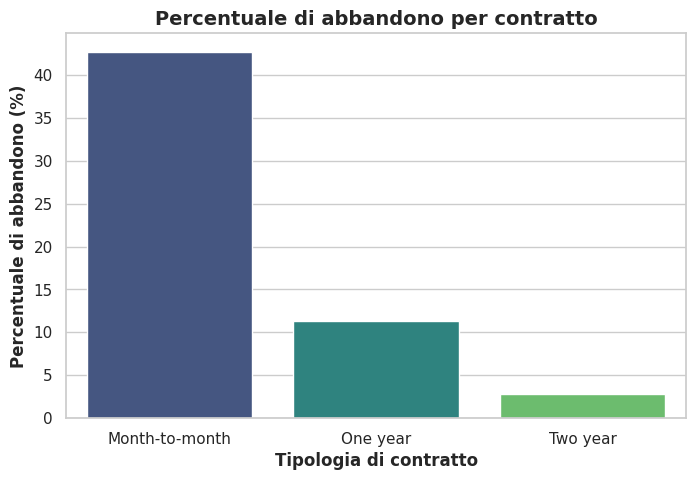

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configuriamo lo stile
sns.set_theme(style='whitegrid')
plt.figure(figsize=(8, 5))

# Creamos el gráfico de barras usando la serie resumida 'churn_yes'
sns.barplot(x=churn_yes.index, y=churn_yes.values, hue=churn_yes.index, palette='viridis', legend=False)

plt.title('Percentuale di abbandono per contratto', fontsize=14, fontweight='bold')
plt.xlabel('Tipologia di contratto', fontsize=12, fontweight='bold')
plt.ylabel('Percentuale di abbandono (%)', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.show()

L'analisi del tasso di abbandono in relazione alla tipologia contrattuale evidenzia una differenza significativa tra i clienti con contratto mensile e quelli con contratti annuali o biennali.

In particolare, i clienti con contratto mensile presentano un tasso di churn del 42,71%, rispetto all'11,27% dei clienti con contratto annuale e al 2,83% di quelli con contratto biennale.

Questi risultati suggeriscono che una maggiore durata contrattuale è associata a una minore probabilità di abbandono.

Dal punto di vista aziendale, potrebbe quindi essere utile incentivare i clienti con contratti mensili a sottoscrivere piani annuali o biennali, attraverso offerte personalizzate, agevolazioni economiche e programmi di fidelizzazione.

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].head(10))

object
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object


In [ ]:
print(df['TotalCharges'].tail(10))

7033    2625.25
7034    6886.25
7035     1495.1
7036      743.3
7037     1419.4
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: TotalCharges, dtype: object


In [ ]:
#convertiamo i valori in numerici
valori_numerici=pd.to_numeric(df['TotalCharges'], errors='coerce')
valori_numerici.isnull().sum()

np.int64(11)

In [ ]:
#ispezioniamo gli 11 problematici
df.loc[valori_numerici.isnull(),['customerID','tenure','TotalCharges']]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [ ]:
#TRASFORMIAMO I VALORI MANCANTI IN NaN
df['TotalCharges']=pd.to_numeric(df['TotalCharges'], errors='coerce')

In [ ]:
#verifichiamo il risultato
df['TotalCharges'].dtype

dtype('float64')

In [ ]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [ ]:
#controlliamo di nuovo le statistiche
df['TotalCharges'].describe()

,TotalCharges
count,7032.000000
mean,2283.300441
std,2266.771362
min,18.800000
25%,401.450000
50%,1397.475000
75%,3794.737500
max,8684.800000


In [ ]:
df[['TotalCharges','tenure','MonthlyCharges']].describe()

,TotalCharges,tenure,MonthlyCharges
count,7032.000000,7043.000000,7043.000000
mean,2283.300441,32.371149,64.761692
std,2266.771362,24.559481,30.090047
min,18.800000,0.000000,18.250000
25%,401.450000,9.000000,35.500000
50%,1397.475000,29.000000,70.350000
75%,3794.737500,55.000000,89.850000
max,8684.800000,72.000000,118.750000


In [ ]:
#conta quanti valori negativi ci sono
(df[['tenure','MonthlyCharges','TotalCharges']]<0).sum()

,0
tenure,0
MonthlyCharges,0
TotalCharges,0


In [ ]:
#controlliamo gli 0
(df[['tenure','MonthlyCharges','TotalCharges']]==0).sum()

,0
tenure,11
MonthlyCharges,0
TotalCharges,0


In [ ]:
#controlliamo le variabili categoriche
df.select_dtypes(include="object").nunique()

,0
customerID,7043
gender,2
Partner,2
Dependents,2
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3
OnlineBackup,3
DeviceProtection,3


In [ ]:
df['InternetService'].value_counts()

,count
InternetService,
Fiber optic,3096
DSL,2421
No,1526


In [ ]:
#cerchiamo se nelle colonne testuali ci sono valori con sapzi all'inizio o alla fine
for colonna in df.select_dtypes(include='object').columns:
  spazi=df[colonna].astype("string").str.strip()!=df[colonna].astype("string")
  if spazi.any():
    print(colonna, spazi.sum())

In [ ]:
#controlliamo per l'ultima volta i valori mancanti
df.isnull().sum().sort_values(ascending=False)

,0
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


In [ ]:
#controlliamo che churn contenga solo le 2 categorie attese
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


### Confronto tra i modelli

Dal confronto tra Regressione Logistica e Random Forest, il modello che ha ottenuto le prestazioni migliori è risultato essere la **Regressione Logistica**, con un'Accuracy di circa **81%**, rispetto al 78% circa ottenuto dalla Random Forest.

La Regressione Logistica ha mostrato risultati migliori anche in termini di Precision, Recall e F1-score. Per questo motivo è stata scelta come modello di riferimento per le successive analisi.

Ora separiamo le informazioni da **prevedere**:
x--> variabile che useremo per la previsione
y--> variabile che volgiamo prevedere, **CHURN**

In [ ]:
X= df.drop(columns=['Churn','customerID'])
Y=df['Churn']

In [ ]:
print("Dimensioni di X:", X.shape)
print("Dimensioni di Y:", Y.shape)

Dimensioni di X: (7043, 19)
Dimensioni di Y: (7043,)


Dividiamo i dati in **Training** (80%) e in **Test**(20%)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train,Y_test= train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [ ]:
print("X_train", X_train.shape)
print("X_test", X_test.shape)
print("Y_train", Y_train.shape)
print("Y_test", Y_test.shape)

X_train (5634, 19)
X_test (1409, 19)
Y_train (5634,)
Y_test (1409,)


In [ ]:
# PREPARIAMO LE VARIABILI
X_train.dtypes

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [ ]:
X_train.select_dtypes(include='number').columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [ ]:
#prepariamo le variabili numeriche
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
colonne_numeriche=X_train.select_dtypes(include='number').columns
colonne_testuali=X_train.select_dtypes(include='object').columns
print("Colonne numeriche:", list(colonne_numeriche))
print("Colonne tesuali:", list(colonne_testuali))

Colonne numeriche: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Colonne tesuali: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
preparazione_numerica= Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
preparazione_tesuale=Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])

In [ ]:
preprocessore=ColumnTransformer(transformers=[('num', preparazione_numerica, colonne_numeriche), ('cat', preparazione_tesuale, colonne_testuali)])

**Regressione** **logistica**

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
modello= Pipeline(steps=[
    ("prepocessore", preprocessore),
    ("classificatore", LogisticRegression(max_iter=1000))
])

**Addestriamo** il modello

In [ ]:
modello.fit(X_train,Y_train)

Pipeline(steps=[('prepocessore',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('classificatore', LogisticRegression(max_iter=1000))])

In [ ]:
#facciamo le prime previsioni
Y_pred=modello.predict(X_test)

In [ ]:
Y_pred[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No'],
      dtype=object)

In [ ]:
#confrontiamo previsione e realtà
confronto=pd.DataFrame({'Valore_reale':Y_test, 'Previsione':Y_pred})
display(confronto.head(10))

,Valore_reale,Previsione
437,No,No
2280,No,Yes
2235,No,No
4460,No,No
3761,No,No
5748,No,Yes
3568,No,No
2976,No,No
5928,No,No
1639,Yes,No


In [ ]:
# calcoliamo l'accuratezza
from sklearn.metrics import accuracy_score
accuratezza=accuracy_score(Y_test,Y_pred)
print("Accuratezza:", accuratezza)
print("Accuratezza percentuale:", accuratezza*100,"%")

Accuratezza: 0.8055358410220014
Accuratezza percentuale: 80.55358410220013 %


In [ ]:
#calcoliamo la matrice di confusione
from sklearn.metrics import confusion_matrix
matrice= confusion_matrix(Y_test, Y_pred)
print(matrice)

[[926 109]
 [165 209]]


In [ ]:
# calcoliamo la recall --> tra tutti i clienti che hanno realmente abbandonato, quanti siamo riusciti a individuare?
from sklearn.metrics import recall_score
recall=recall_score(Y_test,Y_pred, pos_label='Yes')
print("recall", recall)
print("recall percentuale", recall*100, "%")

recall 0.5588235294117647
recall percentuale 55.88235294117647 %


In [ ]:
#calcoliamo la precision --> tra tutti i clienti che il modlelo ha previsto YES quanti hanno realmente abbandonato?
from sklearn.metrics import precision_score
precision=precision_score(Y_test, Y_pred, pos_label='Yes')
print("precision", precision)
print("precision percentuale", precision*100, "%")


precision 0.6572327044025157
precision percentuale 65.72327044025157 %


In [ ]:
#calcoliamo la F1 score --> combina precision e recall in un unico indicatore
from sklearn.metrics import f1_score
f1=f1_score(Y_test,Y_pred, pos_label='Yes')
print("f1", f1)
print("f1 percentuale", f1*100, "%")
#

f1 0.6040462427745664
f1 percentuale 60.40462427745664 %


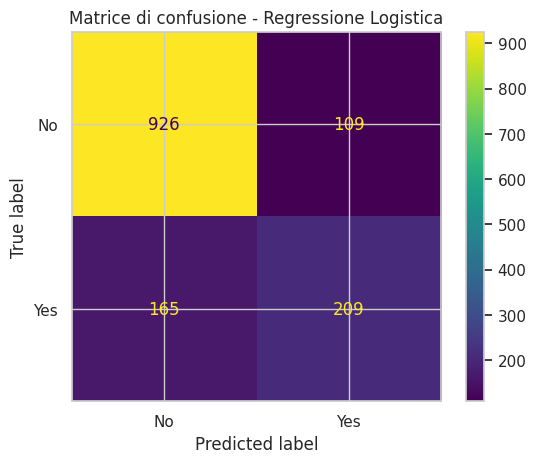

In [ ]:
#visualizziamo la matrice di confusione
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
ConfusionMatrixDisplay.from_predictions(Y_test, Y_pred, labels=['No','Yes'])
plt.title('Matrice di confusione - Regressione Logistica')
plt.show()


**Random** **forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
modello_rf=Pipeline(steps=[('preprocessore', preprocessore),('classificatore', RandomForestClassifier(n_estimators=100, random_state=42))])

Adestriamo il modello sui dati di Training

In [ ]:
modello_rf.fit(X_train, Y_train)

Pipeline(steps=[('preprocessore',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('classificatore', RandomForestClassifier(random_state=42))])

In [ ]:
Y_pred_rf=modello_rf.predict(X_test)

In [ ]:
Y_pred_rf[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes'],
      dtype=object)

In [ ]:
#calcoliamo l'accuracy
accuracy_rf=accuracy_score(Y_test,Y_pred_rf)
print("Accuracy random forest", accuracy_rf*100,"%")

Accuracy random forest 77.78566359119942 %


In [ ]:
#calcoliamo precision, f1 e recall
precision_rf=precision_score(Y_test,Y_pred_rf, pos_label='Yes')
recall_rf=recall_score(Y_test,Y_pred_rf, pos_label='Yes')
f1_rf=f1_score(Y_test,Y_pred_rf, pos_label='Yes')

print("Precision random forest", precision_rf*100,"%")
print("Recall random forest", recall_rf*100,"%")
print("F1 random forest", f1_rf*100,"%")

Precision random forest 60.33898305084746 %
Recall random forest 47.593582887700535 %
F1 random forest 53.21375186846039 %


In [ ]:
#Creaiamo una tabella comparativa
risultati=pd.DataFrame({
    "Modello": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy_score(Y_test,Y_pred), accuracy_rf],
    "Precision": [precision, precision_rf],
    "Recall": [recall, recall_rf],
    "F1-score": [f1, f1_rf]
})
display(risultati.round(4))

,Modello,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Random Forest,0.7779,0.6034,0.4759,0.5321


### Ottimizzazione della soglia di classificazione

La soglia predefinita utilizzata dalla Regressione Logistica è pari a 0,5. Tuttavia, considerando l'obiettivo aziendale di individuare il maggior numero possibile di clienti a rischio di abbandono, abbiamo sperimentato anche soglie inferiori.

In particolare, utilizzando una soglia pari a 0,4, la Recall della classe `Yes` è aumentata dal 56% al 66%. Questo significa che il modello riesce a individuare una quota maggiore dei clienti che effettivamente abbandonano il servizio.

La riduzione della soglia comporta però un aumento dei falsi positivi, ovvero dei clienti segnalati come potenziali abbandoni che in realtà non abbandonano.

Abbiamo quindi scelto di considerare la soglia 0,4, privilegiando la capacità di intercettare i clienti a rischio, pur accettando un aumento dei falsi positivi.

Abbiamo scelto la soglia 0,4 perché consente di individuare correttamente un numero maggiore di clienti che abbandonano effettivamente il servizio. In particolare, la Recall passa dal 56% al 66%, riducendo il numero di falsi negativi. Questo è importante perché l'obiettivo aziendale è intercettare il maggior numero possibile di clienti a rischio di abbandono, così da poter intervenire preventivamente.

Proviamo a migliorare la **Recall**, abbassando la soglia a 0.4

In [ ]:
print(modello.classes_)

['No' 'Yes']


In [ ]:
#calcoliamo la prob di abbandono per ogni cliente del test set
probabilita_yes=modello.predict_proba(X_test)[:,1]
print(probabilita_yes[:10])

[0.04529387 0.68441126 0.05872074 0.40170424 0.02154772 0.60393536
 0.44922498 0.13005522 0.00288077 0.39517899]


In [ ]:
import numpy as np

In [ ]:
Y_pred_soglia= np.where(probabilita_yes >= 0.4, 'Yes', 'No')
print(Y_pred_soglia[:10])

['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No']


In [ ]:
recall_soglia= recall_score(Y_test,Y_pred_soglia, pos_label='Yes')
precision_soglia=precision_score(Y_test,Y_pred_soglia, pos_label='Yes')
F1_soglia=f1_score(Y_test,Y_pred_soglia, pos_label='Yes')
print("Recall", recall_soglia)
print("Precision", precision_soglia)
print("F1", F1_soglia)

Recall 0.6684491978609626
Precision 0.5694760820045558
F1 0.6150061500615006


abbassiamo ulteriormente la soglia a 0.3

In [ ]:
Y_pred_soglia_03= np.where(probabilita_yes >= 0.3, 'Yes', 'No')
print(Y_pred_soglia_03[:10])
recall_03= recall_score(Y_test,Y_pred_soglia_03, pos_label='Yes')
precision_03=precision_score(Y_test,Y_pred_soglia_03, pos_label='Yes')
F1_03=f1_score(Y_test,Y_pred_soglia_03, pos_label='Yes')
print("Recall", recall_03)
print("Precision", precision_03)
print("F1", F1_03)

['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes']
Recall 0.7540106951871658
Precision 0.5193370165745856
F1 0.6150490730643402


In [ ]:
#creiamo una tabella delle soglie
confronto_soglie=pd.DataFrame({
    "Soglia": [0.5,0.4, 0.3],
    "Recall": [recall,recall_soglia, recall_03],
    "Precision": [precision, precision_soglia, precision_03],
    "F1-score": [f1, F1_soglia, F1_03]
})
display(confronto_soglie.round(4))

,Soglia,Recall,Precision,F1-score
0,0.5,0.5588,0.6572,0.604
1,0.4,0.6684,0.5695,0.615
2,0.3,0.7540,0.5193,0.615


### Proposta di strategie aziendali

Alla luce dei risultati ottenuti, si propone di adottare strategie di fidelizzazione mirate principalmente ai clienti con contratto mensile, che presentano un tasso di abbandono significativamente più elevato rispetto ai clienti con contratti annuali e biennali.

Una possibile iniziativa consiste nel proporre, in prossimità della scadenza del contratto mensile, offerte promozionali come la formula «3 mesi al prezzo di 2».

L'obiettivo è incentivare il cliente a prolungare il rapporto con l'azienda, permettendogli di sperimentare il servizio per un periodo più lungo e aumentando le possibilità che decida successivamente di sottoscrivere un contratto annuale.

Le offerte potrebbero essere personalizzate dando priorità ai clienti che il modello predittivo identifica come maggiormente esposti al rischio di abbandono.

È importante confrontare il tasso di abbandono tra i clienti che hanno ricevuto la promozione e quelli che non l'hanno ricevuta, per valutare l'effettiva efficacia dell'iniziativa.

Se il tasso di abbandono rimane elevato anche tra i clienti destinatari dell'offerta, potrebbe essere necessario indagare ulteriormente sulle cause del churn. Ad esempio, l'abbandono potrebbe dipendere da problemi legati all'assistenza clienti, alla qualità del servizio o alla competitività dei prezzi, piuttosto che dalla sola convenienza economica.

In [ ]:
#INTERPRETIAMO LA LOGISTIC REGRESSION
coefficienti=modello.named_steps['classificatore'].coef_[0]
print(coefficienti [:10])

[ 0.05392942 -1.24131879 -0.59639191  0.51670806 -0.16774247 -0.14571922
 -0.16793359 -0.1455281  -0.04313021 -0.27033148]


In [ ]:
nomi_variabili=modello.named_steps['prepocessore'].get_feature_names_out()
print(nomi_variabili[:10])

['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes']


In [ ]:
#variabili più associate a churn
import pandas as pd
importanza=pd.DataFrame({
    'Variabile': nomi_variabili,
    'Coefficiente': coefficienti})
importanza=importanza.sort_values(by='Coefficiente', ascending=False)
display(importanza.head(10).round(4))

,Variabile,Coefficiente
16,cat__InternetService_Fiber optic,0.6400
36,cat__Contract_Month-to-month,0.5793
3,num__TotalCharges,0.5167
35,cat__StreamingMovies_Yes,0.2040
32,cat__StreamingTV_Yes,0.2036
43,cat__PaymentMethod_Electronic check,0.1984
18,cat__OnlineSecurity_No,0.1570
27,cat__TechSupport_No,0.1321
14,cat__MultipleLines_Yes,0.1060
0,num__SeniorCitizen,0.0539


In [ ]:
#variabili meno associate a churn
display(importanza.tail(10).round(4))

,Variabile,Coefficiente
19,cat__OnlineSecurity_No internet service,-0.3011
17,cat__InternetService_No,-0.3011
31,cat__StreamingTV_No internet service,-0.3011
25,cat__DeviceProtection_No internet service,-0.3011
22,cat__OnlineBackup_No internet service,-0.3011
39,cat__PaperlessBilling_No,-0.3433
2,num__MonthlyCharges,-0.5964
15,cat__InternetService_DSL,-0.6524
38,cat__Contract_Two year,-0.7723
1,num__tenure,-1.2413


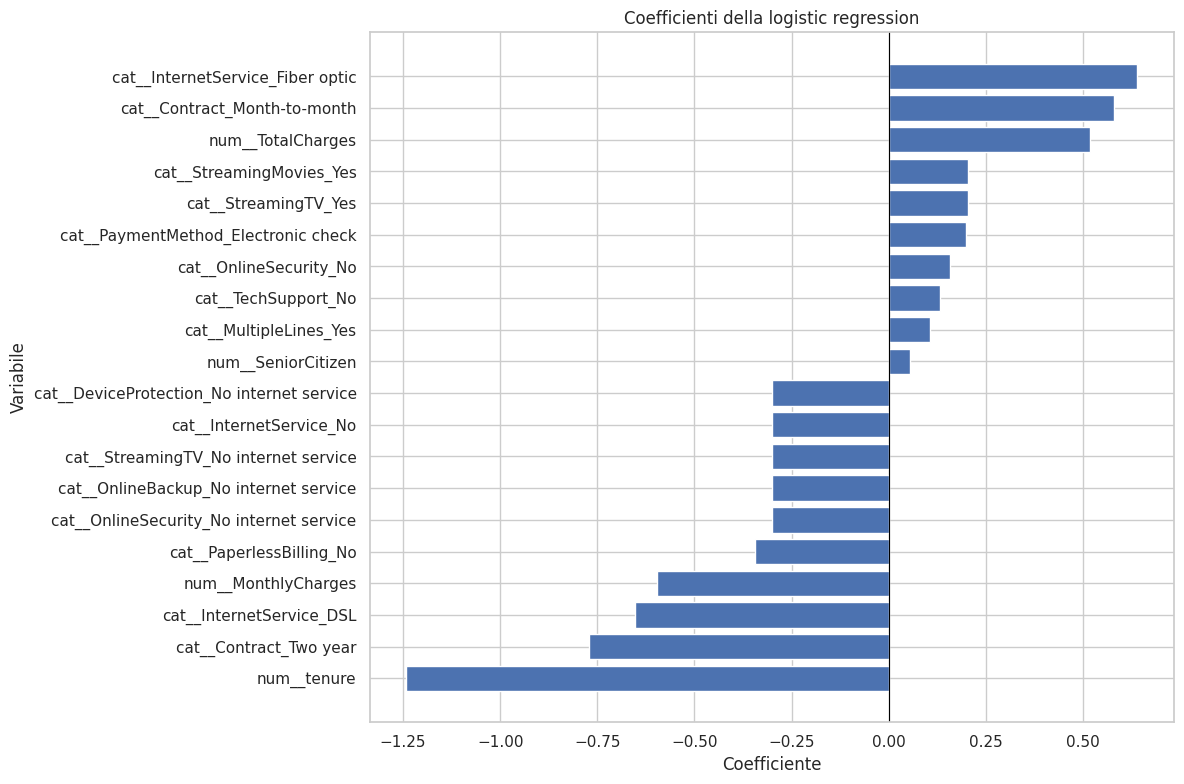

In [ ]:
#creiamo un grafico
import matplotlib.pyplot as plt
importanza_grafico=pd.concat([importanza.head(10), importanza.tail(10)])
importanza_grafico=importanza_grafico.sort_values(by='Coefficiente')
plt.figure(figsize=(12,8))
plt.barh(importanza_grafico['Variabile'], importanza_grafico['Coefficiente'])
plt.axvline(x=0, color='black', linewidth=0.8)
plt.title("Coefficienti della logistic regression")
plt.xlabel("Coefficiente")
plt.ylabel("Variabile")
plt.tight_layout()
plt.show()

## Implicazioni aziendali e strategie di fidelizzazione

I risultati ottenuti attraverso il modello predittivo possono rappresentare un utile supporto alle decisioni aziendali, consentendo di individuare anticipatamente i clienti maggiormente esposti al rischio di abbandono.

L'analisi esplorativa ha evidenziato che i clienti con contratto mensile presentano un tasso di churn significativamente superiore rispetto a quelli con contratti annuali e biennali.

Alla luce di questa evidenza, si propone di adottare strategie di fidelizzazione mirate, tra cui:

- **Offerte promozionali:** proporre agevolazioni economiche, ad esempio la formula «3 mesi al prezzo di 2», per incentivare il rinnovo dei contratti mensili.
- **Promozione dei contratti a lungo termine:** incentivare il passaggio a piani annuali o biennali attraverso condizioni economiche vantaggiose.
- **Interventi personalizzati:** contattare prioritariamente i clienti che il modello identifica come maggiormente a rischio di abbandono.
- **Miglioramento del servizio:** analizzare le eventuali criticità legate all'assistenza clienti e alla qualità dei servizi offerti.

L'efficacia delle iniziative proposte potrebbe essere valutata attraverso test controllati (A/B test), confrontando il tasso di abbandono dei clienti che ricevono le promozioni con quello di un gruppo di controllo.

## Limiti del modello

Nonostante i risultati ottenuti, il modello presenta alcuni limiti che devono essere considerati nell'interpretazione delle previsioni.

In primo luogo, un'Accuracy pari a circa l'81% non garantisce l'individuazione corretta di tutti i clienti che abbandoneranno il servizio. In particolare, con la soglia standard di 0,5, la Recall della classe `Yes` è pari a circa il 56%, evidenziando che una parte dei clienti che effettivamente abbandonano non viene individuata dal modello.

La riduzione della soglia a 0,4 permette di migliorare la capacità di identificare i clienti a rischio, ma comporta anche un aumento dei falsi positivi.

Inoltre, le previsioni dipendono dalle informazioni disponibili nel dataset e dalle relazioni individuate durante l'addestramento. Eventuali fattori non presenti nei dati, come esperienze negative con l'assistenza clienti o offerte della concorrenza, potrebbero influenzare la decisione del cliente di abbandonare il servizio.

Per questi motivi, il modello deve essere considerato uno strumento di supporto alle decisioni aziendali e non un sistema in grado di prevedere con certezza il comportamento futuro dei clienti.

### Possibili miglioramenti del modello

Per migliorare le capacità predittive del modello, sarebbe utile integrare il dataset con ulteriori informazioni relative all'esperienza del cliente e alla qualità del servizio.

In particolare, si potrebbero raccogliere dati riguardanti:

- La frequenza e la gravità dei problemi di connessione.
- Il numero di richieste di assistenza tecnica, comprese quelle a domicilio.
- I costi di attivazione del servizio.
- I costi e le condizioni di recesso dal contratto.

Queste informazioni potrebbero contribuire a individuare ulteriori fattori associati all'abbandono del servizio, permettendo di sviluppare un modello più completo e potenzialmente più efficace.

L'integrazione di nuove variabili, insieme a un successivo addestramento e a una valutazione delle prestazioni, potrebbe migliorare la capacità dell'azienda di individuare preventivamente i clienti a rischio di abbandono.

REPORT DI CLASSIFICAZIONE

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(Y_test, Y_pred, target_names=['No','Yes']))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [ ]:
from sklearn.metrics import confusion_matrix

cm_04 = confusion_matrix(
    Y_test,
    Y_pred_soglia,
    labels=["No", "Yes"]
)

print(cm_04)

[[846 189]
 [124 250]]


# Conclusioni

Il progetto ha affrontato il problema del Customer Churn nel settore delle telecomunicazioni, con l'obiettivo di individuare i clienti maggiormente esposti al rischio di abbandono del servizio attraverso tecniche di Machine Learning.

Dopo una prima fase di analisi esplorativa e pulizia dei dati, sono stati sviluppati e confrontati due modelli di classificazione: Regressione Logistica e Random Forest.

Tra i modelli considerati, la Regressione Logistica ha ottenuto le prestazioni migliori, raggiungendo un'Accuracy di circa l'81%. È stata inoltre sperimentata una soglia di classificazione pari a 0,4, che ha permesso di aumentare la Recall della classe relativa ai clienti che abbandonano il servizio, passando dal 56% al 66%.

L'analisi ha evidenziato una forte associazione tra la tipologia contrattuale e il tasso di abbandono. In particolare, i clienti con contratto mensile risultano maggiormente esposti al rischio di churn rispetto a quelli con contratti annuali e biennali.

Dal punto di vista aziendale, i risultati suggeriscono l'importanza di sviluppare strategie di fidelizzazione mirate, attraverso offerte personalizzate, incentivi al rinnovo e miglioramenti della qualità del servizio.

Nonostante i risultati ottenuti, il modello presenta alcuni limiti e non consente di prevedere con certezza il comportamento futuro dei clienti. L'integrazione di ulteriori informazioni relative all'esperienza del cliente potrebbe contribuire a migliorarne le capacità predittive.

In conclusione, il progetto dimostra come le tecniche di analisi dei dati e Machine Learning possano rappresentare un valido supporto alle decisioni aziendali, trasformando i dati disponibili in informazioni utili per prevenire l'abbandono dei clienti.

In [ ]:
import pandas as pd
import numpy as np

# Classificazione con soglia 0.4
previsioni_finali = np.where(probabilita_yes >= 0.4, "Yes", "No")

# Creazione tabella dei risultati
clienti_rischio = pd.DataFrame({
    "ID_cliente": df.loc[X_test.index, "customerID"],
    "Probabilita_abbandono": probabilita_yes,
    "Previsione": previsioni_finali
})

# Mostriamo i clienti classificati come a rischio
clienti_rischio = clienti_rischio[
    clienti_rischio["Previsione"] == "Yes"
].sort_values(
    by="Probabilita_abbandono", ascending=False
)

clienti_rischio.head(10)

,ID_cliente,Probabilita_abbandono,Previsione
3380,5178-LMXOP,0.855436,Yes
6866,0295-PPHDO,0.832400,Yes
2631,6861-XWTWQ,0.828939,Yes
6365,8884-ADFVN,0.822404,Yes
4585,1069-XAIEM,0.819126,Yes
3346,2545-EBUPK,0.817964,Yes
2797,6023-YEBUP,0.817899,Yes
3727,9057-SIHCH,0.817792,Yes
6894,1400-MMYXY,0.816927,Yes
935,6630-UJZMY,0.812555,Yes


## Individuazione dei clienti a rischio di abbandono

Dopo aver selezionato la soglia di classificazione pari a 0,4, abbiamo applicato il modello ai dati del test set per individuare i clienti con una probabilità stimata di abbandono pari o superiore al 40%.

I clienti classificati come `Yes` sono stati ordinati in base alla probabilità stimata, dal valore più alto al più basso.

Questa procedura permette di individuare i clienti che potrebbero richiedere maggiore attenzione da parte dell'azienda, consentendo di pianificare eventuali interventi di fidelizzazione.

In [ ]:
len(clienti_rischio)

439

### Risultati dell'individuazione dei clienti a rischio

Applicando il modello di Regressione Logistica con una soglia di classificazione pari a 0,4, sono stati individuati 439 clienti potenzialmente a rischio di abbandono su un totale di 1.409 osservazioni presenti nel test set.

Questi clienti rappresentano circa il 31,16% del campione di test.

L'azienda potrebbe utilizzare queste informazioni per definire una lista di clienti da monitorare e sui quali concentrare eventuali iniziative di fidelizzazione.

È importante sottolineare che si tratta di previsioni del modello e non di abbandoni certi: non tutti i clienti classificati come `Yes` interromperanno necessariamente il servizio.